In [2]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal
from langchain_openai.chat_models import ChatOpenAI
from dotenv import load_dotenv
load_dotenv()

True

# TABLE OF CONTENTS 

1. Conditional workflow  <br />
**(also as iterative workflow with multiple conditions )**

# 1) Conditional Workflow

**problem statement** :  Depending on the credit score to determine whether the loan will be sanctioned or not  reply a message 

In [3]:
class Credit_Score(TypedDict):
    credit_score :  int 
    sanctioned  :  bool
    status :  str 

    
    
model =  ChatOpenAI(model="gpt-4.1-mini")

In [4]:
def show_credit_score(state :  Credit_Score) :
    
    return {"score" : state["credit_score"]}


def check_credit(state :  Credit_Score) -> Literal["excellent_score","fair_score","poor_score"]:
    
    if state["credit_score"]  >  700  :
        return "excellent_score"
    
    elif 650 < state["credit_score"] <  700 :
        return  "fair_score"
    else:
        return "poor_score"
        

def excellent_score(state :  Credit_Score):
    
    
    state["sanctioned"]  =  True
    prompt =  f"Write a message depending on the credit score.  :  {state['credit_score']} and {state['sanctioned']}"
    ans =  model.invoke(prompt)    
    return {"status":ans.content }

def fair_score(state  :  Credit_Score):
    
    
    state["sanctioned"]  =  True
    prompt =  f"Write a message depending on the credit score.  :  {state['credit_score']} and {state['sanctioned']}"
    ans =  model.invoke(prompt)    
    return {"status":ans.content }

def poor_score(state :  Credit_Score):
    
    state["sanctioned"]  =  False
    prompt =  f"Write a message depending on the credit score.  :  {state['credit_score']} and {state['sanctioned']}"
    ans =  model.invoke(prompt)    
    return {"status":ans.content }
    
    



        

In [5]:
graph =  StateGraph(Credit_Score)



graph.add_node("show_credit_score",show_credit_score)
graph.add_node("excellent_score",excellent_score)
graph.add_node("fair_score",fair_score)
graph.add_node("poor_score",poor_score)



# 1) The checking condition will not be addressed as the node 
# 2)  and will return the node name. 

graph.add_edge(START,"show_credit_score")
graph.add_conditional_edges("show_credit_score",check_credit)
graph.add_edge("excellent_score",END)
graph.add_edge("fair_score",END)
graph.add_edge("poor_score",END)



workflow =  graph.compile()


In [6]:
data = {"credit_score":800}
final_state =  workflow.invoke(data)

print(final_state["status"])

Your credit score is excellent at 800! You're in a great position to access the best loan terms and credit offers. Keep up the good financial habits!


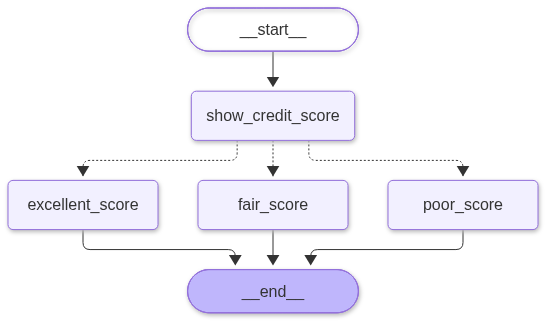

In [7]:

from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())